# Atlas-DeePC: Full-Data Reacher Comparison

**p=8, no graph guidance, K=64, rank 53; seeds 211--310; T_sim=300.**

This is a new 100-rollout development comparison with Select-DPC and contextual-DPC,
not the separate 500-seed evaluation. K and rank were selected on these development
seeds, so these results are not held-out performance.

The controller uses raw, unstandardized linear charts, full L=12 input/output
projection-residual selection, one fixed nearest eligible offline terminal pose,
and Clarabel. The objective contains only tracking, input effort, and initial-output
slack (lambda_ini=100000). There are no coefficient boxes, coefficient penalties,
input-change penalties, or graph waypoints. Each rollout has 12 zero-input warmup
steps followed by 300 controlled steps; T_ini=2 and T_f=10.

**Full data are retained**, including outputs, inputs, fixed reference, one-step
and full-horizon predictions, coefficients g, initial-output slack, initial histories,
all chart-selection residuals, statuses, realized stage costs, and per-step timings.
Projection bases are stored once in `selection_geometry.npz`; exact solver bases
are retained separately in `controller_geometry.npz`, since coefficient coordinates
depend on the basis orientation. The integrity check below verifies reconstruction
of every solved prediction from its saved coefficients. No compaction is applied.

Strict success requires both final-30 and final-100 windows to have mean target
error below 10 mm and maximum error below 20 mm. Median rollout RMSE is the median
of per-seed RMSEs over all 300 controlled steps. Timing summaries discard the first
five steps per rollout. Logging overhead and concurrent jobs affect timing.

The saved comparison audit checks contextual-DPC's initial states and shared Cartesian targets,
and verifies whether Atlas's fixed posture reference matches contextual-DPC's
saved reference. Select-DPC uses Reacher-v4 and no physical warmup, versus
Reacher-v5 and 12 warmup steps here. Its initial controlled state therefore differs.
Select-DPC retains its original offline data, horizon, reference, constraints, and weights;
this is a comparison of configured methods, not an isolated controller ablation.
Native weighted costs must not be compared directly across different objectives.


In [1]:
from pathlib import Path
import os, sys, json, importlib
for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[name] = "1"
os.environ.setdefault("MPLCONFIGDIR", "/tmp/atlas_deepc_mpl")
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/atlas_deepc").is_dir())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from atlas_deepc.benchmarks import reacher_heldout, reacher_mixed_k
from atlas_deepc.benchmarks import atlas_reacher_comparison as study
importlib.reload(reacher_heldout)
importlib.reload(reacher_mixed_k)
importlib.reload(study)
RUN_EXPERIMENT = False
RESULT_DIR = study.RESULT_ROOT
T_sim = study.CONTROL_STEPS
protocol = study.prepare()
print("Results:", RESULT_DIR)
print("Seeds 211--310; p=8, K=64, rank=53, no guidance; steps:", T_sim)
progress = study.report()
print(f"Completed: {progress['completed']}/{progress['requested']}")


Results: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/reacher/atlas_comparison_p8_k64_r53_t300_v1
Seeds 211--310; p=8, K=64, rank=53, no guidance; steps: 300


Completed: 100/100


## Run or Resume
Set `RUN_EXPERIMENT = True` to run missing seeds serially with one numerical thread. Completed full traces are validated and reused. Do not run a second worker for this panel. Interrupting retains complete seeds.

In [2]:
if RUN_EXPERIMENT:
    import subprocess, signal
    process = subprocess.Popen([sys.executable, "-u", "-m", "atlas_deepc.benchmarks.atlas_reacher_comparison"],
        cwd=ROOT, env=dict(os.environ, PYTHONPATH=str(ROOT / "src")),
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1, start_new_session=True)
    try:
        for line in process.stdout:
            print(line, end="", flush=True)
        if process.wait():
            raise RuntimeError("Run stopped; see the error above. Complete traces are retained.")
    except KeyboardInterrupt:
        try:
            os.killpg(process.pid, signal.SIGINT)
            process.wait(timeout=20)
        except ProcessLookupError:
            pass
        except subprocess.TimeoutExpired:
            os.killpg(process.pid, signal.SIGKILL)
            process.wait()
        print("Stopped; rerun to resume.")
    finally:
        process.stdout.close()
else:
    print("Read-only results display; no rollouts launched.")


Read-only results display; no rollouts launched.


## Full-Data Integrity
Retain the exact controller basis orientation and verify every solved trajectory. This uses the frozen atlas and offline dataset; it does not simulate or optimize any new rollout.

In [3]:
directory = study.panel_directory()
paths = [directory / f"seed{s}_control_results.npz" for s in study.SEEDS]
if all(path.exists() for path in paths):
    geometry_path = directory / "controller_geometry.npz"
    signature_hash = study.runner.file_digest(directory / "manifest.json")
    if geometry_path.exists():
        with np.load(geometry_path) as geometry:
            assert geometry["signature_sha256"].item() == signature_hash
            bases = geometry["bases"].copy()
    else:
        with study.protocol_context(), study.runner.controller_context(RESULT_DIR, 8, "terminal") as context:
            bases = context[3].copy()
    assert bases.shape == (64, 120, 53)
    np.testing.assert_allclose(np.swapaxes(bases, 1, 2) @ bases,
                               np.broadcast_to(np.eye(53), (64, 53, 53)), atol=1e-10)
    largest_error, solved_steps = 0., 0
    for path in paths:
        study.validate_full_trace(path, signature_hash)
        with np.load(path, allow_pickle=True) as trace:
            solved = np.isin(trace["status"], ["optimal", "optimal_inaccurate"])
            behavior = np.einsum("tij,tj->ti", bases[trace["chart"][solved]], trace["g_coefficients"][solved])
            expected = np.concatenate([trace["u_ini"][solved],
                trace["planned_u"][solved].reshape(-1, 20),
                trace["y_ini"][solved] + trace["slack"][solved],
                trace["planned_y"][solved].reshape(-1, 80)], axis=1)
            np.testing.assert_allclose(behavior, expected, rtol=1e-7, atol=1e-8)
            if len(expected):
                largest_error = max(largest_error, float(np.max(np.abs(behavior-expected))))
            solved_steps += int(solved.sum())
    if not geometry_path.exists():
        np.savez_compressed(geometry_path, bases=bases, chart_ids=np.arange(64),
            signature_sha256=np.array(signature_hash),
            atlas_sha256=np.array(study.runner.file_digest(study.atlas_path())))
    integrity = {"checked_rollouts": len(paths), "solved_steps": solved_steps,
        "maximum_reconstruction_error": largest_error, "steps_per_rollout": 300,
        "controller_geometry_sha256": study.runner.file_digest(geometry_path)}
    study.runner.save_json(RESULT_DIR / "full_data_integrity.json", integrity)
    display(integrity)
else:
    print("Full integrity check will run after all 100 rollouts complete.")


{'checked_rollouts': 100,
 'solved_steps': 30000,
 'maximum_reconstruction_error': 2.5016645976982943e-09,
 'steps_per_rollout': 300,
 'controller_geometry_sha256': 'cd619e455bd42954fde4a3853d0022d4812acd462ad10b53a19c2ba7c18e732f'}

## Atlas Results
Failed seeds remain included. Statistics are calculated from all 300 saved controlled samples.

In [4]:
report = study.report()
print(f"Completed: {report['completed']}/{report['requested']}")
rows = []
for seed in study.SEEDS:
    path = study.panel_directory() / f"seed{seed}_control_results.npz"
    if path.exists():
        with np.load(path, allow_pickle=True) as trace:
            rows.append(json.loads(trace["summary"].item()))
if rows:
    frame = pd.DataFrame(rows)
    frame["final100_mean_mm"] = 1000*frame["mean_last_100"]
    frame["final100_max_mm"] = 1000*frame["max_last_100"]
    display(frame[["seed", "strict_success", "final100_mean_mm", "final100_max_mm", "rollout_rmse_mm", "unsolved_steps"]])
    print("Failed seeds:", [r["seed"] for r in rows if not r["strict_success"]])
if report["complete"]:
    metrics = report["metrics"]
    keys = ["success_rate", "median_error_mm", "p90_error_mm", "p95_error_mm", "p99_error_mm",
            "median_rollout_rmse_mm", "median_time_ms", "p95_time_ms", "p99_time_ms"]
    display(pd.DataFrame({"Atlas-DeePC": {k: metrics[k] for k in keys}}))
    display(pd.DataFrame(metrics["timing_modules"]))
    audit = report["comparison_audit"]
    print("Paired targets checked:", audit["checked_seeds"])
    print("Contextual-DPC reference mismatches:", audit["contextual_reference_mismatch_seeds"])
    print(audit["note"])


Completed: 100/100


,seed,strict_success,final100_mean_mm,final100_max_mm,rollout_rmse_mm,unsolved_steps
0,211,True,2.641485,2.641485,7.960026,0
1,212,True,2.637012,2.637012,61.481904,0
2,213,True,4.152649,4.152913,115.379844,0
3,214,True,0.944729,0.944732,87.009417,0
4,215,True,1.194163,1.194164,42.662175,0
...,...,...,...,...,...,...
95,306,False,400.269794,400.307310,400.643803,0
96,307,True,1.156425,1.156426,74.834778,0
97,308,True,1.489824,1.489826,67.544075,0
98,309,True,1.823852,1.823975,112.202376,0


Failed seeds: [222, 236, 245, 252, 254, 278, 281, 290, 296, 306]


,Atlas-DeePC
success_rate,90.000000
median_error_mm,1.781083
p90_error_mm,10.837489
p95_error_mm,151.325073
p99_error_mm,244.993190
median_rollout_rmse_mm,61.674992
median_time_ms,20.487230
p95_time_ms,27.451608
p99_time_ms,49.869489


,module,mean_ms,median_ms,p95_ms,p99_ms,share_of_mean_total
0,Chart localization,0.177134,0.162666,0.225127,0.401631,0.008101
1,Terminal-reference selection,0.001305,0.001167,0.001791,0.002458,0.000060
2,Graph routing,0.004340,0.003875,0.005750,0.012833,0.000198
3,Linear subspace retrieval,0.000870,0.000750,0.001042,0.001416,0.000040
4,QP construction and solve,21.653169,20.285312,27.172748,49.659735,0.990280
5,Other control-loop work,0.028878,0.026625,0.033917,0.070003,0.001321
6,Total online control,21.865696,20.487230,27.451608,49.869489,1.000000


Paired targets checked: 100
Contextual-DPC reference mismatches: []
Select-DPC uses Reacher-v4 without physical warmup, versus Reacher-v5 and 12 zero-input steps here. It retains its original offline data, horizon, reference, constraints, and weights. This is not an otherwise-identical benchmark; native weighted costs are not directly comparable.


## Paired Physical Metrics
These methods share the development seed panel and 300-step horizon. Different reference and constraint conventions are noted above. Timings come from separate sessions; the Atlas run may overlap the 500-seed evaluation.

In [5]:
comparison = []
for method, directory in [("Atlas-DeePC", study.panel_directory()),
                          ("Select-DPC", study.SELECT_ROOT), ("Contextual-DPC", study.CONTEXTUAL_ROOT)]:
    paths = [directory / f"seed{s}_control_results.npz" for s in study.SEEDS]
    if not all(p.exists() for p in paths):
        continue
    errors, rmses, times, success = [], [], [], []
    for path in paths:
        with np.load(path, allow_pickle=True) as trace:
            distance = trace["distance"]
            assert distance.shape == (300,)
            errors.append(1000*distance[-100:].mean())
            rmses.append(1000*np.sqrt(np.mean(distance**2)))
            times.append(1000*trace["control_compute_time_s"][5:])
            success.append(all(distance[-n:].mean() < .01 and distance[-n:].max() < .02 for n in (30, 100)))
    timing = np.concatenate(times)
    comparison.append({"method": method, "success_percent": 100*np.mean(success),
        "median_error_mm": np.median(errors), "p90_error_mm": np.percentile(errors, 90),
        "p95_error_mm": np.percentile(errors, 95), "p99_error_mm": np.percentile(errors, 99),
        "median_rollout_rmse_mm": np.median(rmses), "median_time_ms": np.median(timing),
        "p95_time_ms": np.percentile(timing, 95), "p99_time_ms": np.percentile(timing, 99)})
display(pd.DataFrame(comparison).set_index("method").T)


method,Atlas-DeePC,Select-DPC,Contextual-DPC
success_percent,90.000000,80.000000,85.000000
median_error_mm,1.781083,3.324236,5.886626
p90_error_mm,10.837489,34.226541,10.927324
p95_error_mm,151.325073,52.977470,12.821202
p99_error_mm,244.993190,69.981987,85.324858
median_rollout_rmse_mm,61.674992,43.984497,32.944479
median_time_ms,20.487230,1598.827166,92.512459
p95_time_ms,27.451608,3637.844206,123.091413
p99_time_ms,49.869489,5158.921650,145.826668


## Inspect a Full Rollout

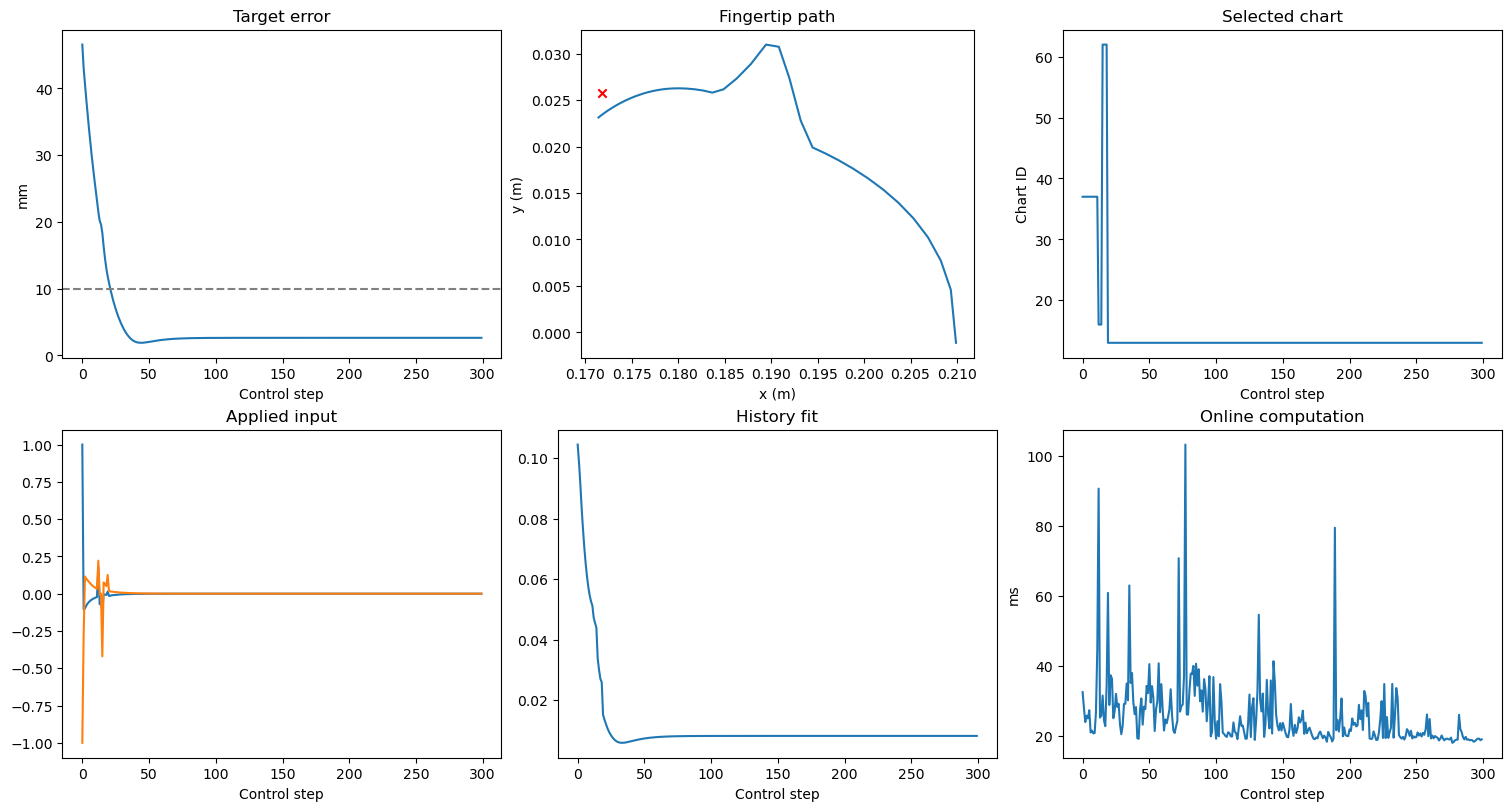

Saved arrays: {'y': (300, 8), 'u': (300, 2), 'pred': (300, 8), 'ref': (300, 8), 'distance': (300,), 'prediction_error_xy': (300,), 'status': (300,), 'chart': (300,), 'goal_chart': (300,), 'next_chart': (300,), 'path_length': (300,), 'matrix_columns': (300,), 'g_min': (300,), 'localization_time_s': (300,), 'routing_time_s': (300,), 'matrix_preparation_time_s': (300,), 'solve_time_s': (300,), 'control_compute_time_s': (300,), 'terminal_overlap_active': (300,), 'goal_selection_time_s': (300,), 'goal_index': (300,), 'goal_route_cost': (300,), 'final_goal': (8,), 'u_ini': (300, 4), 'y_ini': (300, 16), 'planned_u': (300, 10, 2), 'planned_y': (300, 10, 8), 'g_coefficients': (300, 53), 'slack': (300, 16), 'qp_equality_residual': (300,), 'objective': (300,), 'initial_fit_residual': (300,), 'selection_windows': (300, 120), 'selection_residuals': (300, 64), 'selection_tie_count': (300,), 'warmup_u': (12, 2), 'warmup_y': (12, 8), 'y_before': (300, 8), 'target_xy': (2,), 'stage_tracking_cost': (300

In [6]:
PLOT_SEED = 211
path = study.panel_directory() / f"seed{PLOT_SEED}_control_results.npz"
if path.exists():
    with np.load(path, allow_pickle=True) as saved:
        a = {k: saved[k] for k in saved.files}
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
    axes[0,0].plot(a["distance"]*1000)
    axes[0,0].axhline(10, color="grey", ls="--")
    axes[0,0].set(title="Target error", ylabel="mm", xlabel="Control step")
    axes[0,1].plot(a["y"][:,6], a["y"][:,7])
    axes[0,1].scatter(*a["target_xy"], marker="x", color="red")
    axes[0,1].set(title="Fingertip path", aspect="equal", xlabel="x (m)", ylabel="y (m)")
    axes[0,2].plot(a["chart"])
    axes[0,2].set(title="Selected chart", ylabel="Chart ID", xlabel="Control step")
    axes[1,0].plot(a["u"])
    axes[1,0].set(title="Applied input", xlabel="Control step")
    axes[1,1].plot(np.linalg.norm(a["slack"], axis=1), label="Initial-output slack")
    axes[1,1].set(title="History fit", xlabel="Control step")
    axes[1,2].plot(1000*a["control_compute_time_s"])
    axes[1,2].set(title="Online computation", ylabel="ms", xlabel="Control step")
    fig.savefig(RESULT_DIR / f"diagnostic_seed{PLOT_SEED}.png", dpi=150)
    plt.show()
    print("Saved arrays:", {k: v.shape for k,v in a.items() if k != "summary"})
else:
    print("This seed has not completed yet.")
